# Projeto NP2: Aprendizado Supervisionado — Classificação em Among Us com Random Forest
**Aluno:** Wans Ranier | **Disciplina:** Aprendizado Supervisionado | **Prof.:** Alexandre Magno

> **Como ler este notebook.** Ele alterna *texto explicativo* e *código*. Cada célula de código tem comentários que explicam o que cada linha faz, e cada resultado é seguido de uma seção "**Como ler**" que interpreta os números. Células marcadas com **[adicionada]** foram incluídas na revisão para reforçar o aprendizado e a análise.

**Roteiro:** 1. Contexto → 1.1–1.6 Matemática do Random Forest → 2. Dados → 3. Dicionário e vazamento → 4. Relevância das variáveis → 5. Avaliação e curvas de validação → 6. Outliers, superfície de decisão e erros → 7. Conclusões → Glossário.

## 1. Contexto do Problema

**O jogo.** *Among Us* é um jogo de dedução social. Cada partida tem **Tripulantes** (que vencem concluindo todas as tarefas ou descobrindo e *ejetando* os Impostores em votação) e **Impostores** (que vencem eliminando tripulantes e sabotando). O resultado é **coletivo**: ou o time vence ou perde.

**O problema.** Dado o resumo de uma partida do *Player 1* (papel, tarefas feitas, se foi assassinado, duração etc.), queremos **prever se ele venceu ou perdeu**. É um problema de **classificação binária supervisionada**:
- **Supervisionado:** treinamos com exemplos em que já sabemos a resposta (o `Outcome`).
- **Binário:** só existem duas respostas possíveis, Vitória (`1`) ou Derrota (`0`).

**O dataset.** 100 partidas do Player 1: [Among Us Dataset — Kaggle](https://www.kaggle.com/datasets/ruchi798/among-us-dataset/data). Há 58 vitórias e 42 derrotas (58% / 42%, levemente desbalanceado).

**Por que é difícil?** O dataset só enxerga **um** jogador de até 10. Se o time perdeu porque *outro* tripulante foi mal, essa informação não está nos dados. Esse limite aparecerá várias vezes ao longo do notebook.

### Glossário mínimo (para ler o resto sem tropeçar)
| Termo | Significado simples |
| :--- | :--- |
| **Feature** (atributo) | Cada coluna usada como *pergunta* para o modelo (ex.: `Task Completed`). |
| **Target** (alvo) | A coluna que queremos prever (`Outcome`, aqui chamada `Target`). |
| **Treino / Teste** | O modelo estuda no treino e é "examinado" no teste, que ele nunca viu. |
| **Hiperparâmetro** | Configuração escolhida *por nós* antes de treinar (ex.: profundidade máxima). |
| **Overfitting** (sobreajuste) | Decorar o treino, inclusive o ruído, e ir mal em dados novos. |
| **Underfitting** (subajuste) | Modelo simples demais, que nem aprende bem o treino. |
| **Viés** | Erro por simplificar demais. |
| **Variância** | erro por ser sensível demais aos dados de treino. |


## 1.1 Fundamentação Matemática do Algoritmo Random Forest

### Intuição em uma frase
Uma **árvore de decisão** é uma sequência de perguntas de sim/não ("`Murdered` = 1?", "`Game Length` ≤ 820 s?"). Sozinha, ela é instável: mudando um pouco os dados, muda a árvore inteira (**alta variância**). O **Random Forest** treina **muitas árvores diferentes** e deixa todas votarem. Pense em perguntar a 100 pessoas independentes em vez de a uma só: os erros individuais tendem a se cancelar.

Formalmente, é um método de *ensemble* baseado em **Bagging** (*Bootstrap Aggregating*): combina $B$ árvores treinadas sobre amostras com reposição e subconjuntos aleatórios de atributos.

### Passo 1 — Bootstrap (amostragem com reposição)
Para cada árvore $b = 1,\dots,B$, sorteia-se, **com reposição**, uma amostra de $n$ partidas do treino (mesmo tamanho do treino). Uma partida pode aparecer 2 ou 3 vezes; outras não aparecem.

A chance de uma partida específica **não** ser sorteada em nenhum dos $n$ sorteios é $(1 - 1/n)^n \to e^{-1} \approx 0{,}368$. Logo, cada árvore enxerga em média **~63,2%** das partidas distintas, e os **~36,8% restantes** são as amostras *out-of-bag* (OOB), usadas como validação gratuita (ver Célula 10). A Célula 3 simula isso.

### Passo 2 — Cada árvore é construída por partição recursiva gulosa
Aqui entram o **critério de custo** e o **mecanismo de otimização** que o enunciado cobra:
- **Função de custo (impureza):** o Índice de Gini (seção 1.2).
- **Otimização:** *busca gulosa* (*greedy*). Em cada nó, a árvore testa os cortes possíveis e escolhe o que mais reduz a impureza **naquele momento**, sem olhar para o futuro. Não há gradiente nem garantia de ótimo global.
- **Custo de uma divisão:** para cada um dos $m$ atributos candidatos, ordenam-se os valores e testam-se os pontos de corte; custo ≈ $O(m \cdot n \log n)$ por nó.
- **Parada:** o nó vira folha ao atingir `max_depth`, ao ficar puro, ou se um corte deixaria menos de `min_samples_leaf` partidas em algum filho.


### 1.2 Critério de Divisão: Impureza e Ganho de Gini
Em cada nó interno $D$, a árvore busca o atributo $j$ e o limiar de corte $s$ que particionam os dados em $D_{\text{esq}} = \{(\mathbf{x}_i, y_i) \in D \mid x_{i,j} \le s\}$ e $D_{\text{dir}} = \{(\mathbf{x}_i, y_i) \in D \mid x_{i,j} > s\}$. A impureza de um nó é medida pelo **Índice de Gini**:

$$Gini(D) = 1 - \sum_{c=1}^{k} p_c^2$$

onde $p_c$ é a proporção de observações da classe $c \in \{0, 1\}$ no nó $D$.

**Como interpretar o Gini:**
- É a probabilidade de **errar** se você sortear uma partida do nó e der a ela um rótulo sorteado segundo as proporções do próprio nó.
- Nó **puro** (só vitórias ou só derrotas): $Gini = 1 - 1^2 = 0$ (impureza mínima).
- Nó **50/50**: $Gini = 1 - 0{,}5^2 - 0{,}5^2 = 0{,}5$ (impureza máxima com 2 classes).
- **Por que o quadrado "penaliza" a impureza?** A soma $\sum p_c^2$ é *máxima* quando uma classe domina, e cai quando as classes se misturam. Como o Gini é $1 - \sum p_c^2$, ele é *baixo* para nós puros e *sobe* conforme a mistura aumenta.

O corte ótimo $(j^*, s^*)$ maximiza a redução ponderada de impureza (**Ganho de Gini**):

$$\Delta Gini(D, j, s) = Gini(D) - \left( \frac{|D_{\text{esq}}|}{|D|} Gini(D_{\text{esq}}) + \frac{|D_{\text{dir}}|}{|D|} Gini(D_{\text{dir}}) \right)$$

**Exemplo numérico** (executado na Célula 3): pai com 5 V e 5 D → $Gini = 0{,}50$. Corte em filho esquerdo (4 V, 1 D) com $Gini = 0{,}32$ e filho direito (1 V, 4 D) com $Gini = 0{,}32$. Impureza ponderada $= \tfrac{5}{10}(0{,}32) + \tfrac{5}{10}(0{,}32) = 0{,}32$. **Ganho $= 0{,}50 - 0{,}32 = 0{,}18$.** A árvore escolhe, entre todos os cortes candidatos, o de maior ganho.

### 1.3 Descorrelação das Árvores (*Feature Bagging*) e Votação
Se todas as árvores pudessem escolher entre todas as variáveis, a mais forte (ex.: `Game Length`) dominaria o primeiro corte de todas, e as árvores ficariam parecidas, e a "votação" perderia valor. Por isso, a cada divisão são sorteados apenas $m$ atributos candidatos dentre os $p$ disponíveis:

$$m = \lfloor \sqrt{p} \rfloor$$

Como o dataset possui $p = 8$ variáveis preditoras, cada nó avalia $m = \lfloor \sqrt{8} \rfloor = 2$ atributos por corte (padrão `max_features='sqrt'` do scikit-learn).

**Regra de decisão.** Na inferência, a predição final é obtida por **votação majoritária** entre as $B$ árvores:

$$\hat{y} = \text{moda}\left\{ h_1(\mathbf{x}), h_2(\mathbf{x}), \dots, h_B(\mathbf{x}) \right\}$$

*Detalhe de implementação:* o scikit-learn, na verdade, calcula a **média das probabilidades** de cada árvore, $\hat{P}(y=1\mid \mathbf{x}) = \frac{1}{B}\sum_{b} P_b(y=1\mid\mathbf{x})$, e prevê Vitória se $\hat{P} > 0{,}5$. É uma votação "suave" (*soft voting*) que quase sempre coincide com a maioria simples.

**Por que isso reduz a variância?** Se cada árvore tem variância $\sigma^2$ e a correlação média entre elas é $\rho$, a variância da média de $B$ árvores é:

$$\text{Var}\left(\frac{1}{B}\sum_b h_b\right) = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2$$

Aumentar $B$ zera o segundo termo; sobra $\rho\sigma^2$. O *feature bagging* e o bootstrap existem para **diminuir $\rho$**. Consequência prática: **mais árvores não causam overfitting**, apenas estabilizam o resultado (Célula 10).

### 1.4 Balanceamento de Classes (`class_weight='balanced'`)
Para compensar a assimetria entre Derrotas ($0$) e Vitórias ($1$), aplica-se ponderação inversamente proporcional à frequência de cada classe no cálculo da impureza de Gini:

$$w_c = \frac{N}{k \cdot N_c}$$

onde $N$ é o total de amostras de treino, $k = 2$ é o número de classes e $N_c$ é a quantidade de amostras da classe $c$.

**Com os nossos dados** (Célula 3): $N = 75$, $N_0 = 31$ derrotas, $N_1 = 44$ vitórias → $w_0 = 75/(2\cdot31) \approx 1{,}21$ e $w_1 = 75/(2\cdot44) \approx 0{,}85$. Cada derrota "vale" mais que cada vitória, e o peso total das duas classes se iguala (≈ 37,5 cada). Efeito: errar uma Derrota custa mais, e o modelo deixa de preferir sempre prever a classe majoritária.

### 1.5 Intuição Geométrica
Cada corte da árvore tem a forma $x_j \le s$: um plano **paralelo a um eixo**. Em 2D, a fronteira de decisão de uma árvore é um conjunto de **retângulos**. A floresta tira a média de muitas árvores com cortes ligeiramente diferentes, o que **suaviza** os degraus e torna a fronteira mais estável (veja a superfície 2D na seção 6). Como cada corte só compara um atributo com um limiar, **não é necessário normalizar a escala** das variáveis, diferente de SVM ou modelos lineares.

### 1.6 Hiperparâmetros usados e o que cada um controla
| Hiperparâmetro | Valor usado | Papel | Efeito se for **muito baixo** | Efeito se for **muito alto** |
| :--- | :---: | :--- | :--- | :--- |
| `n_estimators` | 100 | Nº de árvores | Média ruidosa e instável | Estabiliza; só aumenta o tempo |
| `max_depth` | 3 | Máx. de cortes em sequência | **Underfitting** (viés alto) | **Overfitting** (variância alta) |
| `min_samples_leaf` | 3 | Mín. de partidas por folha | Folhas minúsculas que memorizam ruído | Folhas grandes demais (viés alto) |
| `max_features` | `sqrt` (= 2) | Atributos sorteados por nó | Árvores muito diferentes (mais viés) | Árvores parecidas (menos ganho do ensemble) |
| `class_weight` | `balanced` | Pesos das classes no Gini | — | — |
| `bootstrap` | `True` | Amostragem com reposição | — | — |
| `random_state` | 42 | Semente do sorteio | — | — |

Com apenas **75 partidas de treino**, regularização forte (`max_depth=3`, `min_samples_leaf=3`) é prudente: há poucos dados para sustentar árvores profundas.


## 2. Descrição do Dataset e Pré-Processamento

O `User1.csv` tem **13 colunas originais**. Usamos 9 (8 *features* + 1 *target*) e descartamos 4. Todas as colunas usadas viram **números**, pois o scikit-learn não aceita texto.

| Atributo | Coluna original | Tipo | Transformação Aplicada | Papel no Jogo |
| :--- | :--- | :--- | :--- | :--- |
| `Is_Imposter` | `Team` | Binária (0/1) | `Imposter -> 1`, `Crewmate -> 0` | Define a facção do Player 1 |
| `All Tasks Completed` | idem | Binária (0/1) | `Yes -> 1`; `No` e `-` -> 0 | Conclusão total das tarefas |
| `Murdered` | idem | Binária (0/1) | `Yes -> 1`; `No` e `-` -> 0 | Eliminado por impostor |
| `Ejected` | idem | Binária (0/1) | `Yes -> 1`; `No` -> 0 | Eliminado em votação |
| `Task Completed` | idem | Discreta (0–8) | `- -> 0` (imputação estrutural) | Tarefas concluídas pelo jogador |
| `Imposter Kills` | idem | Discreta (0–5) | `- -> 0` (0 para Tripulantes) | Eliminações feitas como Impostor |
| `Sabotages Fixed` | idem | Discreta (0–4) | `- -> 0` (0 para Impostores) | Sabotagens reparadas |
| `Game Length` | idem | Contínua (s) | Texto `"Xm Ys"` convertido em segundos | Duração total da partida |
| `Outcome` *(Target)* | idem | Binária (0/1) | `Loss -> 0`, `Win -> 1` | Resultado da partida |

**Colunas descartadas:** `Game Completed Date` e `Region/Game Code` (identificadores de sessão, sem valor preditivo), `Rank Change` (consequência direta do resultado, **vazamento**) e `Time to complete all tasks` (preenchida só em parte das partidas).

**Por que não precisa de normalização?** Árvores comparam `x ≤ s`; multiplicar uma coluna por 1000 só muda o valor de `s`, não a ordem dos pontos. A escala é irrelevante.

### Nota Técnica sobre Outliers (Critério de Tukey)
**O que é:** *outlier* é um valor muito distante do restante. A regra de Tukey considera outlier quem está fora de $[Q_1 - 1{,}5\cdot IQR,\; Q_3 + 1{,}5\cdot IQR]$, onde $IQR = Q_3 - Q_1$ é a "largura" dos 50% centrais dos dados.

Para `Game Length` ($Q_1 = 532{,}2\text{s}$, $Q_3 = 934{,}2\text{s}$, $IQR = 402{,}0\text{s}$) os limites são $-70{,}8\text{s}$ e $1537{,}2\text{s}$ (calculados na Célula 11). O limite inferior é **negativo** por ser um artefato da fórmula simétrica aplicada a uma variável estritamente positiva e assimétrica à direita, portanto **nenhuma partida é outlier univariado** (a mais longa tem 1453 s).

**Atenção:** existe **1 partida com `Game Length = 0 s`** (índice 72 do CSV: Impostor, Vitória, `Task Completed = '-'`). Provavelmente é um registro incompleto. O critério de Tukey **não** a detecta (0 está dentro dos limites), então ela foi mantida; é uma limitação a registrar. As anomalias relevantes do problema são **contextuais/multivariadas** (seção 6).


### 3. Dicionário de Dados e Tratamento Definitivo das Colunas

Regras finais aplicadas às 13 colunas originais de `User1.csv`:

#### Síntese das Decisões de Engenharia de Atributos
1. **Descarte de 4 colunas inadequadas:** `Game Completed Date`, `Region/Game Code`, `Rank Change` e `Time to complete all tasks`.
2. **Codificação binária enxuta:** em `All Tasks Completed` e `Murdered`, `Yes = 1` e `No / '-' = 0`. Como `Is_Imposter` já separa os papéis, o algoritmo distingue um tripulante que sobreviveu (`Is_Imposter=0, Murdered=0`) de um impostor (`Is_Imposter=1, Murdered=0`) sem *One-Hot Encoding*.
3. **Coerência nas contagens:** em `Imposter Kills`, `Task Completed` e `Sabotages Fixed`, `'-'` e `NaN` foram preenchidos com `0`, pois refletem a ausência daquela ação naquele papel.

#### O que significa "sem vazamento de dados" (*data leakage*)?
*Vazamento* ocorre quando o modelo recebe, no treino, informação que **não existiria** no momento real de uso ou que vem do teste. Cuidados tomados:
- **Partição antes de qualquer análise:** o `train_test_split` vem primeiro; relevância das variáveis, curvas de validação e ajuste de hiperparâmetros usam **só o treino**. O teste só é usado na avaliação final.
- **Target fora das features:** `Outcome` não entra em `X`.
- **Coluna consequência do alvo removida:** `Rank Change` (`++`/`--`) é consequência direta de vencer/perder.
- **Estratificação:** `stratify=y` mantém ~58% de vitórias em treino e teste.

> **Ressalva honesta.** As features restantes (`Murdered`, `Ejected`, `Game Length`, tarefas...) só são conhecidas **ao final** da partida. Portanto o modelo **não é um preditor "ao vivo"**: ele descreve o desfecho a partir do *resumo pós-jogo*. O problema foi formulado assim deliberadamente. Para prever durante a partida, seria preciso usar apenas informações disponíveis até aquele instante.


In [14]:
# =====================================================================
# CÉLULA 1 — Importações, leitura do CSV e construção do DataFrame tratado
# =====================================================================
# pandas / numpy  -> manipular tabelas e números
# matplotlib / seaborn -> gráficos
# sklearn -> o "kit" de Machine Learning (partição, modelo, métricas)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, validation_curve,StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import classification_report, confusion_matrix,roc_auc_score, f1_score
from sklearn.inspection import DecisionBoundaryDisplay

# 1. Carregamento e função de conversão temporal (minutos/segundos -> segundos)
# O CSV guarda a duração como texto ("07m 04s"). O modelo só entende números,
# então convertemos tudo para segundos: 07m 04s -> 7*60 + 4 = 424.
df_raw = pd.read_csv('User1.csv')
def converter_tempo_segundos(tempo_str):
  if pd.isna(tempo_str) or str(tempo_str).strip() == '-':
    return np.nan
  total = 0
  for parte in str(tempo_str).strip().split():   # "07m 04s" -> ["07m", "04s"]
    if 'm' in parte:
      total += int(parte.replace('m', '')) * 60  # minutos -> segundos
    elif 's' in parte:
      total += int(parte.replace('s', ''))       # segundos
  return total

# 2. Construção do DataFrame tratado (8 features + 1 target)
# Criamos um DataFrame NOVO e vazio, copiando só as colunas que vamos usar.
# Target: 1 se a partida foi Vitória ("win"), 0 se foi Derrota.
df = pd.DataFrame()
df['Target'] = (df_raw['Outcome'].astype(str).str.strip().str.lower() == 'win').astype(int)
# Is_Imposter: 1 se o Player 1 foi Impostor naquela partida, 0 se foi Tripulante.
df['Is_Imposter'] = (df_raw['Team'].astype(str).str.strip().str.lower() == 'imposter').astype(int)

# Colunas Yes/No viram 1/0. O que não for "yes" (No, "-", vazio) vira 0.
for col in ['All Tasks Completed', 'Murdered', 'Ejected']:
  df[col] = (df_raw[col].astype(str).str.strip().str.lower() == 'yes').astype(int)

# Contagens: o traço "-" significa "não se aplica" (ex.: tripulante não tem abates) -> 0.
for col in ['Task Completed', 'Imposter Kills', 'Sabotages Fixed']:
  df[col] = pd.to_numeric(df_raw[col].replace('-', 0), errors='coerce').fillna(0).astype(int)

df['Game Length'] = df_raw['Game Length'].apply(converter_tempo_segundos).astype(int)


In [15]:
# =====================================================================
# CÉLULA 2 — Conferência do DataFrame e partição treino/teste
# =====================================================================
# 3. Inspeção final dos tipos e das primeiras linhas tratadas
# df.info() confirma: 100 linhas, 9 colunas, nenhuma com valor nulo, todas numéricas.
print("--- Estrutura Final do Dataset Tratado ---")
df.info()
display(df.head())

# 4. Particionamento estratificado (75% treino / 25% teste) sem vazamento de dados
# X = as perguntas (features); y = a resposta que queremos prever (target).
X = df.drop(columns=['Target'])
y = df['Target']
# test_size=0.25  -> 25 partidas ficam "trancadas" para a prova final
# random_state=42 -> semente: garante que o sorteio seja sempre o mesmo (reprodutível)
# stratify=y      -> mantém a mesma proporção de Vitórias/Derrotas nos dois grupos
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"\nTreino: {X_train.shape[0]} partidas | Teste: {X_test.shape[0]} partidas")


--- Estrutura Final do Dataset Tratado ---
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Target               100 non-null    int64
 1   Is_Imposter          100 non-null    int64
 2   All Tasks Completed  100 non-null    int64
 3   Murdered             100 non-null    int64
 4   Ejected              100 non-null    int64
 5   Task Completed       100 non-null    int64
 6   Imposter Kills       100 non-null    int64
 7   Sabotages Fixed      100 non-null    int64
 8   Game Length          100 non-null    int64
dtypes: int64(9)
memory usage: 7.2 KB


,Target,Is_Imposter,All Tasks Completed,Murdered,Ejected,Task Completed,Imposter Kills,Sabotages Fixed,Game Length
0,1,0,0,1,0,3,0,2,424
1,0,0,1,0,0,7,0,1,981
2,1,0,0,0,0,3,0,0,693
3,1,1,0,0,0,0,2,0,485
4,0,0,0,0,0,4,0,0,310



Treino: 75 partidas | Teste: 25 partidas


In [3]:
# =====================================================================
# CÉLULA 3 (adicionada) — Gini e Bootstrap "na mão"
# =====================================================================
# Objetivo: ver com números simples o que o Random Forest calcula por dentro.

# ---------- (a) Índice de Gini de um nó ----------
def gini(n_vitorias, n_derrotas):
    """Gini = 1 - soma das proporções ao quadrado. 0 = nó puro; 0,5 = nó 50/50."""
    total = n_vitorias + n_derrotas
    if total == 0:
        return 0.0
    p_vit = n_vitorias / total
    p_der = n_derrotas / total
    return 1 - (p_vit**2 + p_der**2)

# Exemplo ILUSTRATIVO (números inventados só para aprender):
# nó-pai com 10 partidas (5 V e 5 D) cortado em dois filhos de 5 partidas.
g_pai = gini(5, 5)          # 0,50  (máxima mistura)
g_esq = gini(4, 1)          # filho esquerdo: 4 V e 1 D
g_dir = gini(1, 4)          # filho direito:  1 V e 4 D
impureza_ponderada = (5/10) * g_esq + (5/10) * g_dir   # média ponderada pelo tamanho
print("--- Exemplo ilustrativo de Ganho de Gini ---")
print(f"Gini do pai      = {g_pai:.3f}")
print(f"Gini filho esq.  = {g_esq:.3f} | Gini filho dir. = {g_dir:.3f}")
print(f"Impureza ponderada dos filhos = {impureza_ponderada:.3f}")
print(f"Ganho de Gini = {g_pai:.3f} - {impureza_ponderada:.3f} = {g_pai - impureza_ponderada:.3f}")

# Agora com os dados REAIS: o nó raiz de qualquer árvore contém todo o treino.
n_v = int(y_train.sum())            # nº de vitórias no treino
n_d = len(y_train) - n_v            # nº de derrotas no treino
print("\n--- Gini do nó raiz (treino real) ---")
print(f"Treino: {n_v} vitórias e {n_d} derrotas -> Gini = {gini(n_v, n_d):.3f}")

# Efeito do class_weight='balanced':  w_c = N / (k * N_c)
N, k = len(y_train), 2
w_der = N / (k * n_d)
w_vit = N / (k * n_v)
print(f"\nPesos balanceados: derrota = {w_der:.3f} | vitória = {w_vit:.3f}")
print(f"Peso total Derrota = {n_d * w_der:.1f} | Peso total Vitória = {n_v * w_vit:.1f}  (iguais!)")
print(f"Gini do raiz com pesos = {gini(n_v * w_vit, n_d * w_der):.3f}  (o modelo passa a ver o nó como 50/50)")

# ---------- (b) Bootstrap: amostragem COM reposição ----------
# Cada árvore do Random Forest treina numa amostra do mesmo tamanho do treino,
# sorteada com reposição. Quantas partidas DIFERENTES entram, em média?
rng = np.random.default_rng(42)
n = len(X_train)
fracoes = []
for _ in range(1000):
    indices_sorteados = rng.integers(0, n, size=n)           # sorteia n índices, podendo repetir
    fracoes.append(len(np.unique(indices_sorteados)) / n)    # fração de partidas distintas
print("\n--- Bootstrap (1000 repetições simuladas) ---")
print(f"Fração média de partidas distintas por amostra: {np.mean(fracoes):.3f}")
print(f"Valor teórico 1-(1-1/n)^n = {1 - (1 - 1/n)**n:.3f}  (tende a 1 - 1/e ≈ 0,632)")
print(f"Ou seja, ~{100*(1-np.mean(fracoes)):.1f}% das partidas ficam de fora de cada árvore (amostras out-of-bag).")


--- Exemplo ilustrativo de Ganho de Gini ---
Gini do pai      = 0.500
Gini filho esq.  = 0.320 | Gini filho dir. = 0.320
Impureza ponderada dos filhos = 0.320
Ganho de Gini = 0.500 - 0.320 = 0.180

--- Gini do nó raiz (treino real) ---
Treino: 44 vitórias e 31 derrotas -> Gini = 0.485

Pesos balanceados: derrota = 1.210 | vitória = 0.852
Peso total Derrota = 37.5 | Peso total Vitória = 37.5  (iguais!)
Gini do raiz com pesos = 0.500  (o modelo passa a ver o nó como 50/50)

--- Bootstrap (1000 repetições simuladas) ---
Fração média de partidas distintas por amostra: 0.633
Valor teórico 1-(1-1/n)^n = 0.635  (tende a 1 - 1/e ≈ 0,632)
Ou seja, ~36.7% das partidas ficam de fora de cada árvore (amostras out-of-bag).


# 4. Descoberta de Padrões e Seleção de Atributos

Existem várias formas de perguntar "qual coluna importa?". Cada uma responde a uma pergunta diferente:

| Método | Pergunta que responde | Captura relação não linear? | Limitação |
| :--- | :--- | :---: | :--- |
| **Correlação de Pearson** | As duas colunas sobem/descem juntas em linha reta? | Não | Cega a padrões que não são lineares |
| **Informação Mútua (MI)** | Saber a feature reduz a incerteza sobre o alvo? | Sim | Olha uma feature por vez (ignora interações) |
| **Importância de Gini** | Quanto a feature reduziu a impureza nas árvores? | Sim | Favorece variáveis contínuas com muitos cortes possíveis |
| **Permutation Importance** | Quanto o desempenho cai se eu **embaralhar** a feature? | Sim | Instável com poucos dados de teste |

Abaixo, a **Célula 4 [adicionada]** mostra Pearson, e a Célula 5 mostra MI e Gini.


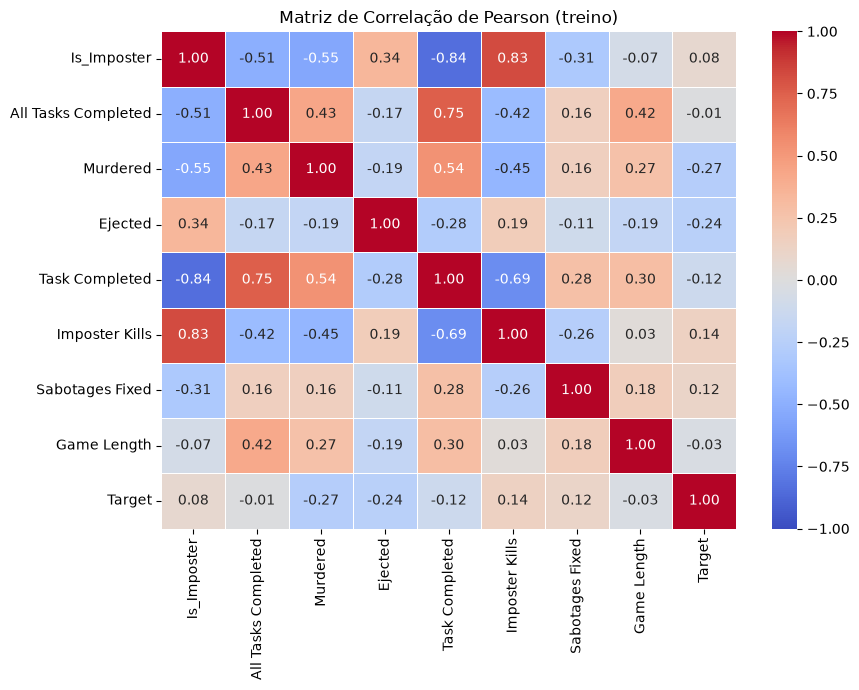

--- Correlação de cada feature com o Target (ordenada por força) ---
Murdered              -0.269
Ejected               -0.243
Imposter Kills         0.142
Task Completed        -0.119
Sabotages Fixed        0.115
Is_Imposter            0.078
Game Length           -0.034
All Tasks Completed   -0.010
Name: Target, dtype: float64

--- Taxa de vitória por papel e por ter sido assassinado (treino) ---


taxa_vitoria  n_partidas
Is_Imposter Murdered                          
0           0                0.762          21
            1                0.441          34
1           0                0.650          20

--- Taxa de vitória por ter sido ejetado (treino) ---


,taxa_vitoria,n_partidas
Ejected,,
0,0.611,72
1,0.000,3


In [4]:
# =====================================================================
# CÉLULA 4 (adicionada) — Correlação de Pearson entre as colunas (somente TREINO)
# =====================================================================
# Pearson mede a relação LINEAR entre duas colunas: vai de -1 a +1.
#   +1 = sobem juntas | -1 = uma sobe e a outra desce | 0 = sem relação linear.
# Usamos só o treino para não "espiar" o teste antes da hora.
treino = X_train.copy()
treino['Target'] = y_train
corr = treino.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=0.5)
plt.title('Matriz de Correlação de Pearson (treino)')
plt.tight_layout()
plt.show()

print("--- Correlação de cada feature com o Target (ordenada por força) ---")
print(corr['Target'].drop('Target').sort_values(key=abs, ascending=False).round(3))

# Taxa de vitória por situação (descritivo, só treino): ajuda a ler os números acima.
print("\n--- Taxa de vitória por papel e por ter sido assassinado (treino) ---")
display(treino.groupby(['Is_Imposter', 'Murdered'])['Target'].agg(taxa_vitoria='mean', n_partidas='count').round(3))
print("--- Taxa de vitória por ter sido ejetado (treino) ---")
display(treino.groupby('Ejected')['Target'].agg(taxa_vitoria='mean', n_partidas='count').round(3))


### Como ler a matriz de Pearson (Célula 4)
- **Cada quadrado** mostra a correlação entre duas colunas (−1 a +1). A última linha/coluna (`Target`) é a que interessa para prever.
- **Correlação de cada feature com o alvo (todas fracas):** `Murdered` −0,27 e `Ejected` −0,24 são as mais fortes e **negativas** (ser assassinado ou ejetado associa-se a menos vitórias). `Imposter Kills` +0,14, `Task Completed` −0,12, `Sabotages Fixed` +0,12 e `Is_Imposter` +0,08 são fracas. `Game Length` (−0,03) e `All Tasks Completed` (−0,01) são praticamente nulas **do ponto de vista linear**.
- **Leitura prática (taxa de vitória no treino):** tripulante que **não** foi assassinado venceu **76%** das vezes (21 partidas); assassinado, **44%** (34 partidas); impostor, **65%** (20 partidas). Já os 3 casos de `Ejected = 1` no treino foram derrotas, mas 3 partidas é amostra pequena demais para concluir.
- **Colinearidade entre features** (redundância): `Task Completed` × `Is_Imposter` ≈ −0,84 e `Imposter Kills` × `Is_Imposter` ≈ +0,83, pois impostores não fazem tarefas e tripulantes não matam. Árvores lidam bem com isso, mas a importância tende a se **dividir** entre colunas redundantes.
- **Moral da história:** nenhuma coluna isolada prediz bem o resultado. Isso antecipa que o modelo terá desempenho **moderado**.


In [5]:
# =====================================================================
# CÉLULA 5 — Informação Mútua x Importância de Gini
# =====================================================================
# Treina o modelo balanceado para extrair a Importância de Gini (e já deixa pronto para as próximas seções)
# n_estimators=100     -> 100 árvores na floresta
# max_depth=3          -> cada árvore pode fazer no máximo 3 cortes seguidos
# min_samples_leaf=3   -> toda folha precisa ter pelo menos 3 partidas
# class_weight='balanced' -> Vitória e Derrota passam a "pesar" igual no Gini
# random_state=42      -> semente (resultados reprodutíveis)
rf_bal = RandomForestClassifier(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=3,
    class_weight='balanced',
    random_state=42
)
rf_bal.fit(X_train, y_train)   # .fit() = "aprender com os dados de treino"

# Marca apenas 'Game Length' como contínua e todas as demais como discretas
# (a Informação Mútua usa estimadores diferentes para cada tipo de variável)
discrete_mask = [col != 'Game Length' for col in X_train.columns]

# Informação Mútua: quanto saber o valor da feature reduz a incerteza sobre o Target (0 = nada)
mi_scores = mutual_info_classif(
    X_train, y_train,
    discrete_features=discrete_mask,
    random_state=42
)

df_relevancia = pd.DataFrame({
    'Feature': X_train.columns,
    'Tipo': ['Contínua' if col == 'Game Length' else 'Discreta' for col in X_train.columns],
    'Info_Mutua': np.round(mi_scores, 4),
    # feature_importances_ = soma da redução de Gini que a feature gerou em todas as árvores
    'Importancia_Gini': np.round(rf_bal.feature_importances_, 4)
}).sort_values(by='Importancia_Gini', ascending=False)

display(df_relevancia)


,Feature,Tipo,Info_Mutua,Importancia_Gini
7,Game Length,Contínua,0.0000,0.3301
2,Murdered,Discreta,0.0365,0.2166
4,Task Completed,Discreta,0.0997,0.1669
5,Imposter Kills,Discreta,0.0272,0.1279
6,Sabotages Fixed,Discreta,0.0219,0.0680
1,All Tasks Completed,Discreta,0.0001,0.0411
0,Is_Imposter,Discreta,0.0030,0.0272
3,Ejected,Discreta,0.0365,0.0222


,Feature,Queda_F1_media,Desvio
2,Murdered,0.0736,0.0961
1,All Tasks Completed,0.0103,0.0118
5,Imposter Kills,0.0040,0.0089
6,Sabotages Fixed,0.0032,0.0081
3,Ejected,0.0000,0.0000
0,Is_Imposter,0.0000,0.0000
4,Task Completed,-0.0093,0.0278
7,Game Length,-0.0289,0.0197


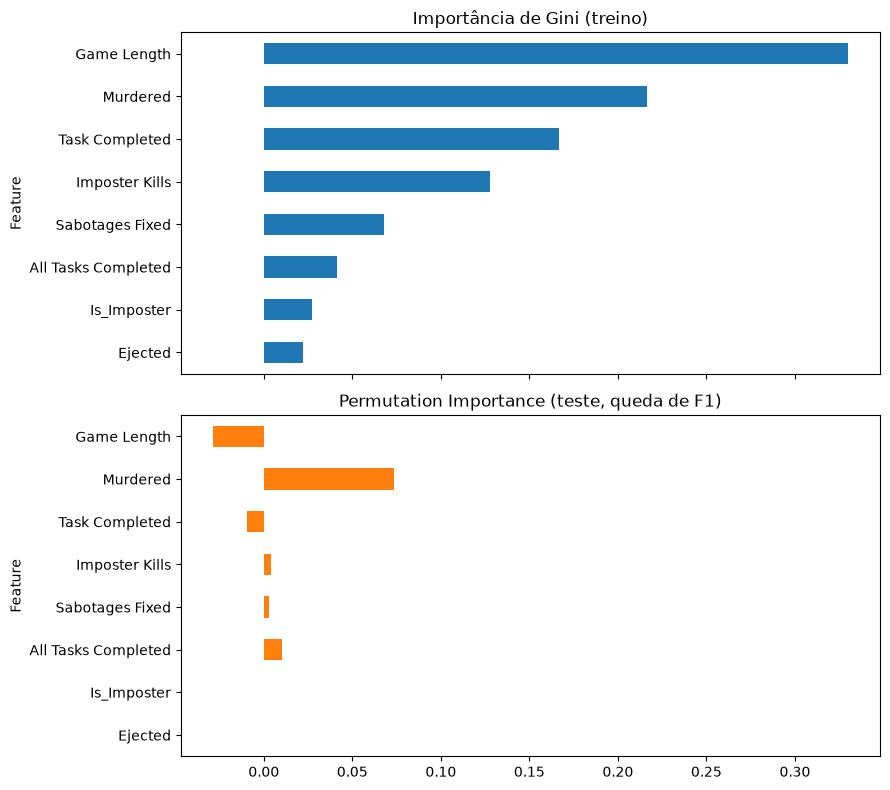

In [6]:
# =====================================================================
# CÉLULA 6 (adicionada) — Permutation Importance (importância por embaralhamento)
# =====================================================================
# Ideia: embaralhar UMA coluna do conjunto de TESTE e ver quanto o F1 cai.
# Se a coluna era útil, embaralhá-la "quebra" o modelo (queda grande).
# Se era irrelevante, nada muda (queda ~0). Valores negativos = embaralhar até ajudou (ruído).
# n_repeats=30 -> repete o embaralhamento 30 vezes e tira a média e o desvio.
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf_bal, X_test, y_test, scoring='f1',
                              n_repeats=30, random_state=42)

df_perm = pd.DataFrame({
    'Feature': X_test.columns,
    'Queda_F1_media': perm.importances_mean.round(4),
    'Desvio': perm.importances_std.round(4)
}).sort_values('Queda_F1_media', ascending=False)
display(df_perm)

# Comparação visual: Gini (calculada no treino) x Permutation (calculada no teste)
comp = df_relevancia.set_index('Feature')[['Importancia_Gini']].join(
    df_perm.set_index('Feature')[['Queda_F1_media']])
comp.sort_values('Importancia_Gini').plot.barh(subplots=True, figsize=(9, 8), legend=False,
                                                title=['Importância de Gini (treino)',
                                                       'Permutation Importance (teste, queda de F1)'])
plt.tight_layout()
plt.show()


### Diagnóstico de Relevância: Informação Mútua, Gini e Permutation (Células 5 e 6)

**Resultados observados:**
- **Informação Mútua:** maior em `Task Completed` (0,0997); `Game Length` tem MI = **0,0000**.
- **Importância de Gini:** `Game Length` lidera (0,330), seguida de `Murdered` (0,217) e `Task Completed` (0,167).
- **Permutation Importance (teste, queda de F1):** só `Murdered` aparece com queda relevante (**+0,074**, mas com desvio de 0,096). `Game Length` mostra queda **negativa** (−0,029): embaralhá-la não prejudicou, e até ajudou levemente.

**Por que os rankings discordam?**
1. **Tipagem discreta na MI:** variáveis de contagem com muitos zeros (`Task Completed`, `Imposter Kills`, `Sabotages Fixed`) devem ser marcadas como discretas (`discrete_features=True`). Tratadas como contínuas, o estimador $k$-NN adiciona ruído para desempatar zeros e subestima a dependência.
2. **Inflação de cortes no Gini (*split-point inflation*):** `Game Length` é a única variável contínua de alta cardinalidade e oferece dezenas de pontos de corte candidatos. Com tantas chances, é fácil achar *por acaso* um corte que pareça bom no treino. O Gini mede o que ajudou **no treino**, e isso inclui ruído.
3. **Interação condicional:** a MI olha uma variável por vez. `Game Length` poderia importar apenas em combinação com outras (ex.: partida curta com abates). A MI não vê isso; o Gini vê.

**O que concluir:** o resultado da permutation (medida no teste) sugere que a alta importância de Gini de `Game Length` é, em boa parte, **ajuste ao treino**, e não sinal que se generaliza. Cuidado ao interpretar: com apenas 25 partidas de teste, os desvios são grandes, então esta evidência é **indicativa, não conclusiva**. O sinal mais consistente nas três métricas é o do **evento `Murdered`** e, em menor grau, `Task Completed`.


## 5. Avaliação do Modelo Regularizado e Curvas de Validação

### Metodologia
- **Partição:** 75 treino / 25 teste, estratificada.
- **Validação cruzada K-Fold (K=5, estratificada):** o treino é dividido em 5 partes; o modelo treina em 4 e valida na 5ª, repetindo 5 vezes. O resultado é a **média** (e o desvio) das 5 validações. É mais confiável que um único corte, pois todas as partidas servem de validação uma vez.
- **Busca de hiperparâmetros:** variamos **dois** hiperparâmetros críticos de forma sistemática, `max_depth` (flexibilidade) e `min_samples_leaf` (regularização), mantendo os demais fixos.
- **Métrica das curvas:** F1 da classe Vitória (`scoring='f1'`).

### Dicionário de métricas
Convenção: classe **positiva = Vitória**. Termos da matriz de confusão: **VP** (previu Vitória e era), **VN** (previu Derrota e era), **FP** (previu Vitória, era Derrota), **FN** (previu Derrota, era Vitória).

| Métrica | Fórmula | Pergunta que responde |
| :--- | :--- | :--- |
| **Acurácia** | $(VP+VN)/\text{total}$ | Quantas previsões acertei no geral? |
| **Precisão** | $VP/(VP+FP)$ | Quando previ Vitória, quantas vezes acertei? |
| **Recall** (sensibilidade) | $VP/(VP+FN)$ | Das vitórias reais, quantas encontrei? |
| **F1** | $2\cdot\frac{P\cdot R}{P+R}$ | Equilíbrio entre precisão e recall (média harmônica: cai se qualquer um for ruim). |
| **Macro avg** | média simples entre as classes | Desempenho médio sem favorecer a classe maior. |
| **ROC-AUC** | área sob a curva ROC | Chance de o modelo dar probabilidade maior a uma vitória sorteada do que a uma derrota sorteada (0,5 = acaso; 1,0 = perfeito). |

**Por que não só acurácia?** Com 58%/42%, um modelo que sempre previsse "Vitória" teria ~58% de acurácia sem aprender nada. F1 por classe, recall e AUC expõem isso.

### Como funciona uma curva de validação
Variamos um hiperparâmetro e plotamos o F1 de **treino** e de **validação**:
- Treino alto e validação baixa, com **distância crescente** → **overfitting** (variância alta).
- Ambos baixos → **underfitting** (viés alto).
- Curvas próximas e razoáveis → bom equilíbrio.


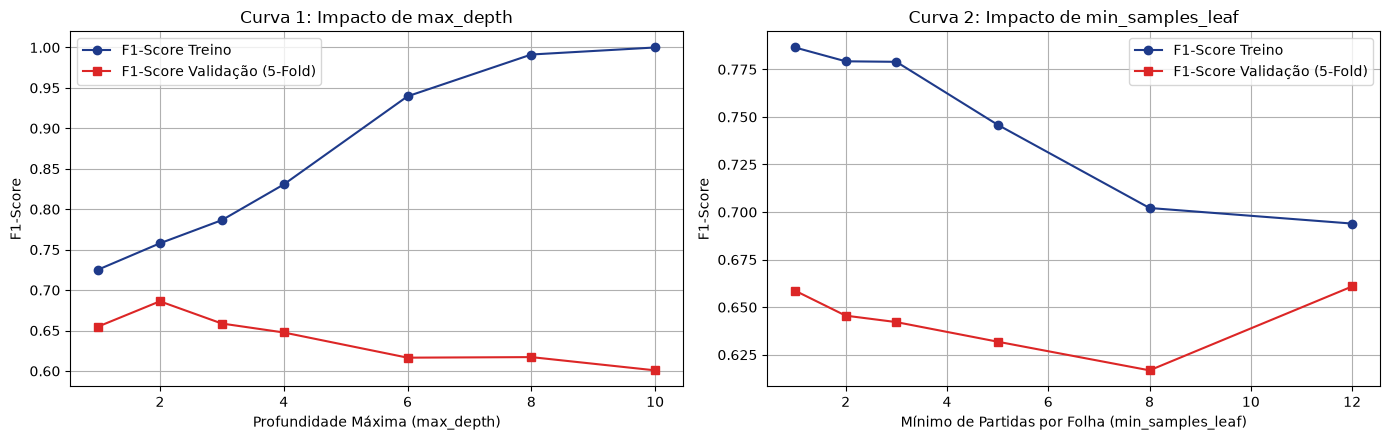

--- Relatório de Classificação no Conjunto de Teste ---
              precision    recall  f1-score   support

 Derrota (0)       0.58      0.64      0.61        11
 Vitória (1)       0.69      0.64      0.67        14

    accuracy                           0.64        25
   macro avg       0.64      0.64      0.64        25
weighted avg       0.64      0.64      0.64        25

ROC-AUC Score: 0.695


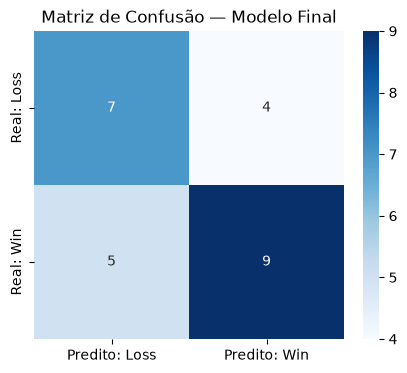

In [7]:
# =====================================================================
# CÉLULA 7 — Curvas de validação + modelo final + métricas + matriz de confusão
# =====================================================================
# 1. Curvas de Validação para 2 Hiperparâmetros Críticos (Viés vs Variância)
# validation_curve: para cada valor do hiperparâmetro, treina o modelo 5 vezes (5-Fold
# estratificado) e devolve o F1 de TREINO e o F1 de VALIDAÇÃO de cada rodada.
# Treino alto + validação baixa = sobreajuste (overfitting).
# Ambos baixos = subajuste (underfitting).
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# --- Hiperparâmetro 1: max_depth (Profundidade Máxima das Árvores) ---
profundidades = [1, 2, 3, 4, 6, 8, 10]
train_scores_d, val_scores_d = validation_curve(
    RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    X_train, y_train,
    param_name='max_depth',
    param_range=profundidades,
    cv=StratifiedKFold(5),
    scoring='f1'
)
axes[0].plot(profundidades, train_scores_d.mean(axis=1), label='F1-Score Treino', color='#1e3a8a', marker='o')
axes[0].plot(profundidades, val_scores_d.mean(axis=1), label='F1-Score Validação (5-Fold)', color='#dc2626', marker='s')
axes[0].set_title('Curva 1: Impacto de max_depth')
axes[0].set_xlabel('Profundidade Máxima (max_depth)')
axes[0].set_ylabel('F1-Score')
axes[0].legend(loc='best')
axes[0].grid(True)

# --- Hiperparâmetro 2: min_samples_leaf (Mínimo de Amostras por Folha) ---
folhas = [1, 2, 3, 5, 8, 12]
train_scores_l, val_scores_l = validation_curve(
    RandomForestClassifier(n_estimators=100, max_depth=3, class_weight='balanced', random_state=42),
    X_train, y_train,
    param_name='min_samples_leaf',
    param_range=folhas,
    cv=StratifiedKFold(5),
    scoring='f1'
)
axes[1].plot(folhas, train_scores_l.mean(axis=1), label='F1-Score Treino', color='#1e3a8a', marker='o')
axes[1].plot(folhas, val_scores_l.mean(axis=1), label='F1-Score Validação (5-Fold)', color='#dc2626', marker='s')
axes[1].set_title('Curva 2: Impacto de min_samples_leaf')
axes[1].set_xlabel('Mínimo de Partidas por Folha (min_samples_leaf)')
axes[1].set_ylabel('F1-Score')
axes[1].legend(loc='best')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# 2. Treinamento do Modelo Regularizado (com class_weight='balanced' para corrigir viés de classe)
modelo_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=3,
    class_weight='balanced',
    random_state=42
)
modelo_final.fit(X_train, y_train)
y_pred = modelo_final.predict(X_test)                 # classe prevista (0 ou 1)
y_proba = modelo_final.predict_proba(X_test)[:, 1]    # probabilidade prevista de Vitória (0 a 1)

print("--- Relatório de Classificação no Conjunto de Teste ---")
print(classification_report(y_test, y_pred, target_names=['Derrota (0)', 'Vitória (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.3f}")

# 3. Matriz de Confusão
# Linhas = classe REAL | Colunas = classe PREVISTA
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predito: Loss', 'Predito: Win'],
            yticklabels=['Real: Loss', 'Real: Win'])
plt.title('Matriz de Confusão — Modelo Final')
plt.show()


### Como ler os resultados da Célula 7

**Curva 1 (`max_depth`):**

| max_depth | 1 | 2 | 3 | 4 | 6 | 8 | 10 |
| :--- | :-: | :-: | :-: | :-: | :-: | :-: | :-: |
| F1 treino | 0,73 | 0,76 | 0,79 | 0,83 | 0,94 | 0,99 | 1,00 |
| F1 validação | 0,66 | 0,69 | 0,66 | 0,65 | 0,62 | 0,62 | 0,60 |

- O F1 de **treino sobe até ~1,0** (a árvore decora os dados) enquanto o de **validação cai** de ~0,69 para ~0,60. A distância crescente é o **overfitting**.
- Não há *underfitting* nítido: a validação já parte de ~0,66 em `max_depth=1`. O ponto aproximado de melhor validação é `max_depth=2` (0,686); `max_depth=3` (0,659) está a 0,027 de distância, diferença **dentro do ruído** de uma validação cruzada com 75 partidas. Optou-se por `max_depth=3` como compromisso (um pouco mais de flexibilidade, ainda longe da região de sobreajuste).

**Curva 2 (`min_samples_leaf`):**

| min_samples_leaf | 1 | 2 | 3 | 5 | 8 | 12 |
| :--- | :-: | :-: | :-: | :-: | :-: | :-: |
| F1 treino | 0,79 | 0,78 | 0,78 | 0,75 | 0,70 | 0,69 |
| F1 validação | 0,66 | 0,65 | 0,64 | 0,63 | 0,62 | 0,66 |

- Com folhas pequenas (1–3) a lacuna treino–validação é de ~0,13–0,14: sobreajuste. Ao exigir folhas maiores o treino cai (menos memorização) e as curvas se aproximam: em 12, a lacuna é de apenas ~0,03.
- A validação **não é monótona** (cai até 8 e sobe em 12): oscilações de ~0,02–0,04 são ruído da validação cruzada com 75 partidas, e não uma tendência firme.
- Nota: como `max_depth=3` já limita muito a árvore, `min_samples_leaf` tem efeito moderado aqui.

**Modelo final** (`max_depth=3`, `min_samples_leaf=3`, `class_weight='balanced'`), no teste de 25 partidas:
- Acurácia **0,64**; F1 macro **0,64**; ROC-AUC **0,695**.
- Matriz de confusão: **7** VN, **4** FP, **5** FN, **9** VP. O modelo não está enviesado para uma só classe: acerta ~64% das derrotas e ~64% das vitórias.


In [8]:
# =====================================================================
# CÉLULA 8 (adicionada) — Métricas calculadas "na mão" a partir da matriz de confusão
# =====================================================================
# Convenção: classe POSITIVA = Vitória (1). ravel() devolve [VN, FP, FN, VP].
vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()
print(f"VP (previu Vitória e era Vitória)  = {vp}")
print(f"VN (previu Derrota e era Derrota)  = {vn}")
print(f"FP (previu Vitória, era Derrota)   = {fp}")
print(f"FN (previu Derrota, era Vitória)   = {fn}")

acuracia   = (vp + vn) / (vp + vn + fp + fn)   # acertos totais / total
precisao   = vp / (vp + fp)                    # das previsões "Vitória", quantas acertaram
recall_vit = vp / (vp + fn)                    # das Vitórias reais, quantas o modelo achou
f1_vit     = 2 * precisao * recall_vit / (precisao + recall_vit)   # média harmônica
recall_der = vn / (vn + fp)                    # das Derrotas reais, quantas o modelo achou
print(f"\nAcurácia          = {acuracia:.3f}")
print(f"Precisão (Vitória)= {precisao:.3f}")
print(f"Recall   (Vitória)= {recall_vit:.3f}")
print(f"F1       (Vitória)= {f1_vit:.3f}")
print(f"Recall   (Derrota)= {recall_der:.3f}")
print("\nConfira: estes valores devem bater com o classification_report acima.")

# Validação cruzada do modelo final: média E desvio dos 5 folds (mede a estabilidade).
from sklearn.model_selection import cross_val_score
for nome, metrica in [('F1 (Vitória)', 'f1'), ('F1 macro', 'f1_macro'), ('ROC-AUC', 'roc_auc')]:
    s = cross_val_score(modelo_final, X_train, y_train, cv=StratifiedKFold(5), scoring=metrica)
    print(f"CV 5-Fold | {nome:13s}: {s.mean():.3f} ± {s.std():.3f}   (folds: {np.round(s, 2)})")


VP (previu Vitória e era Vitória)  = 9
VN (previu Derrota e era Derrota)  = 7
FP (previu Vitória, era Derrota)   = 4
FN (previu Derrota, era Vitória)   = 5

Acurácia          = 0.640
Precisão (Vitória)= 0.692
Recall   (Vitória)= 0.643
F1       (Vitória)= 0.667
Recall   (Derrota)= 0.636

Confira: estes valores devem bater com o classification_report acima.
CV 5-Fold | F1 (Vitória) : 0.642 ± 0.070   (folds: [0.59 0.62 0.78 0.63 0.59])
CV 5-Fold | F1 macro     : 0.574 ± 0.082   (folds: [0.52 0.6  0.72 0.5  0.52])
CV 5-Fold | ROC-AUC      : 0.607 ± 0.080   (folds: [0.5  0.63 0.74 0.6  0.56])


### Como ler a Célula 8 (métricas na mão e validação cruzada)
- As fórmulas calculadas manualmente **batem** com o `classification_report`: isso confirma que você entende de onde cada número vem. Ex.: Precisão (Vitória) $= 9/(9+4) = 0{,}692$; Recall (Vitória) $= 9/(9+5) = 0{,}643$; Recall (Derrota) $= 7/(7+4) = 0{,}636$.
- **Validação cruzada do modelo final:** F1 (Vitória) $0{,}642 \pm 0{,}070$; F1 macro $0{,}574 \pm 0{,}082$; ROC-AUC $0{,}607 \pm 0{,}080$.
- **Comparação CV × teste:** o F1 de CV (0,64) e o do teste (0,67 para Vitória; 0,64 macro) são **compatíveis**: não há sinal de que o modelo "decorou" o treino. Já o AUC do teste (0,695) é um pouco maior que o da CV (0,607 ± 0,08): o teste teve sorte moderada, e o desempenho "verdadeiro" provavelmente está mais perto de **0,60–0,70**.
- **Incerteza do teste:** com 25 partidas, **cada erro altera a acurácia em 4 pontos** ($1/25$) e o recall de Derrota em ~9 pontos ($1/11$). Diferenças de 1 ou 2 partidas são ruído estatístico.


In [9]:
# =====================================================================
# CÉLULA 9 (adicionada) — Efeito do class_weight: modelo SEM balanceamento x COM balanceamento
# =====================================================================
# Mesmos hiperparâmetros, mesma semente; a ÚNICA diferença é o class_weight.
rf_sem_peso = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=3,
                                     class_weight=None, random_state=42)
rf_sem_peso.fit(X_train, y_train)
pred_sem = rf_sem_peso.predict(X_test)
proba_sem = rf_sem_peso.predict_proba(X_test)[:, 1]

print("--- SEM class_weight (None) ---")
print(classification_report(y_test, pred_sem, target_names=['Derrota (0)', 'Vitória (1)']))
print(f"ROC-AUC: {roc_auc_score(y_test, proba_sem):.3f}")
print("Matriz de confusão [linhas=real, colunas=previsto]:")
print(confusion_matrix(y_test, pred_sem))

# Tabela-resumo lado a lado
resumo = pd.DataFrame({
    'Sem class_weight': [(pred_sem == y_test).mean(),
                         (pred_sem[y_test == 0] == 0).mean(),
                         f1_score(y_test, pred_sem, average='macro'),
                         roc_auc_score(y_test, proba_sem)],
    'Com class_weight=balanced': [(y_pred == y_test).mean(),
                                  (y_pred[y_test == 0] == 0).mean(),
                                  f1_score(y_test, y_pred, average='macro'),
                                  roc_auc_score(y_test, y_proba)]
}, index=['Acurácia', 'Recall Derrota', 'F1 macro', 'ROC-AUC']).round(3)
display(resumo)


--- SEM class_weight (None) ---
              precision    recall  f1-score   support

 Derrota (0)       0.50      0.27      0.35        11
 Vitória (1)       0.58      0.79      0.67        14

    accuracy                           0.56        25
   macro avg       0.54      0.53      0.51        25
weighted avg       0.54      0.56      0.53        25

ROC-AUC: 0.682
Matriz de confusão [linhas=real, colunas=previsto]:
[[ 3  8]
 [ 3 11]]


,Sem class_weight,Com class_weight=balanced
Acurácia,0.560,0.640
Recall Derrota,0.273,0.636
F1 macro,0.510,0.638
ROC-AUC,0.682,0.695


### Como ler a Célula 9 (efeito do `class_weight`)
| | Sem `class_weight` | Com `balanced` |
| :--- | :-: | :-: |
| Acurácia | 0,56 | **0,64** |
| Recall de Derrota | **0,27** | **0,64** |
| F1 macro | 0,51 | **0,64** |
| ROC-AUC | 0,68 | 0,695 |

- Sem pesos, o modelo "aposta" na classe majoritária: acerta 79% das vitórias, mas apenas **27% das derrotas** (3 de 11).
- Com `balanced`, o recall de Derrota sobe para **64%** (7 de 11) e a acurácia e o F1 macro melhoram. O custo é perder alguns acertos na classe Vitória (recall 0,79 → 0,64).
- O AUC quase não muda (0,68 → 0,695), pois ele mede a **ordenação** das probabilidades, não o ponto de corte de 0,5; os pesos mudam principalmente onde o corte cai.
- **Nuance importante:** na *validação cruzada*, o F1 da classe **Vitória** é maior sem pesos (0,69 vs 0,64), porque prever sempre "Vitória" favorece essa métrica. Por isso, usar **métricas macro** e **recall por classe** é mais justo para comparar os dois.


,n_estimators,Acuracia_OOB,Acuracia_Teste
0,25,0.587,0.60
1,50,0.533,0.64
2,100,0.587,0.64
3,200,0.547,0.64
4,500,0.533,0.64


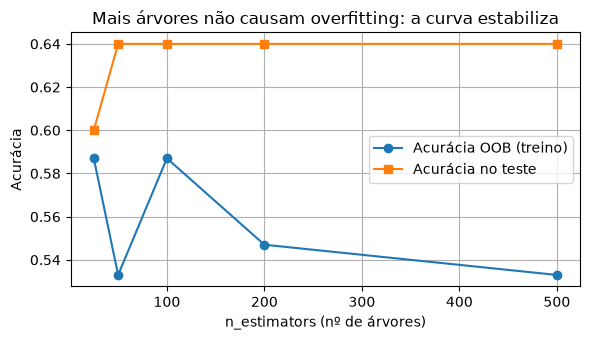

In [10]:
# =====================================================================
# CÉLULA 10 (adicionada) — Erro Out-of-Bag (OOB) e efeito do número de árvores
# =====================================================================
# Cada árvore NÃO viu ~36,8% das partidas (as que ficaram fora do bootstrap).
# Com oob_score=True, cada partida é prevista só pelas árvores que NÃO a viram:
# é uma "validação gratuita", sem separar dados. O resultado é a ACURÁCIA OOB.
import warnings
resultados_oob = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # com poucas árvores, algumas partidas nunca ficam OOB (aviso inofensivo)
    for n_arv in [25, 50, 100, 200, 500]:
        rf_tmp = RandomForestClassifier(n_estimators=n_arv, max_depth=3, min_samples_leaf=3,
                                        class_weight='balanced', oob_score=True, random_state=42)
        rf_tmp.fit(X_train, y_train)
        resultados_oob.append((n_arv, rf_tmp.oob_score_, rf_tmp.score(X_test, y_test)))

df_oob = pd.DataFrame(resultados_oob, columns=['n_estimators', 'Acuracia_OOB', 'Acuracia_Teste']).round(3)
display(df_oob)

plt.figure(figsize=(6, 3.5))
plt.plot(df_oob['n_estimators'], df_oob['Acuracia_OOB'], marker='o', label='Acurácia OOB (treino)')
plt.plot(df_oob['n_estimators'], df_oob['Acuracia_Teste'], marker='s', label='Acurácia no teste')
plt.xlabel('n_estimators (nº de árvores)')
plt.ylabel('Acurácia')
plt.title('Mais árvores não causam overfitting: a curva estabiliza')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Como ler a Célula 10 (OOB e número de árvores)
- A acurácia **OOB** (~0,53–0,59) é estimada com partidas que cada árvore não viu, sem usar o teste. Ela é um pouco menor que a acurácia no teste (0,64), e ambas confirmam um desempenho **moderado**.
- Com `n_estimators` de 50 a 500, a acurácia no teste fica **estável em 0,64**. A OOB oscila entre 0,53 e 0,59, o que equivale a 3 ou 4 partidas em 75, e é variação aleatória, não tendência.
- **Lição:** aumentar o número de árvores **não** causa overfitting; só estabiliza. Os hiperparâmetros que realmente controlam o compromisso viés–variância são a profundidade e o tamanho mínimo da folha.


# 6. Outliers, Superfície de Decisão 2D e Auditoria de Erros

### 6.0 Outliers em `Game Length` (Célula 11, adicionada)
A célula calcula $Q_1$, $Q_3$, $IQR$ e os limites de Tukey, e desenha um **boxplot** (a caixa vai de $Q_1$ a $Q_3$, o traço interno é a mediana; pontos isolados além dos "bigodes" seriam outliers). Resultado: **0 outliers** univariados, mas há **1 partida com duração 0 s**, que a regra não pega (ver nota na seção 2).


Q1 = 532.2s | Q3 = 934.2s | IQR = 402.0s
Limite inferior = -70.8s | Limite superior = 1537.2s
Outliers univariados detectados: 0
Menor duração = 0s | Maior duração = 1453s
Partidas com duração 0 s (registro suspeito, invisível ao critério de Tukey): 1


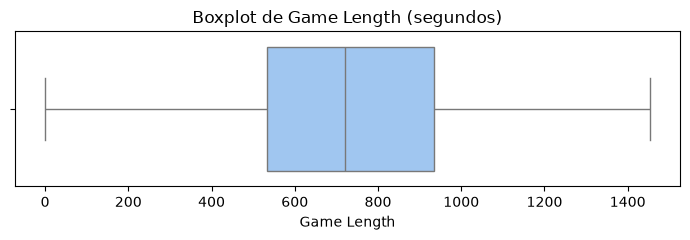

In [11]:
# =====================================================================
# CÉLULA 11 (adicionada) — Critério de Tukey (IQR) para outliers em 'Game Length'
# =====================================================================
# IQR = Q3 - Q1 (a "largura" dos 50% centrais dos dados).
# Regra de Tukey: é outlier quem estiver abaixo de Q1 - 1,5*IQR ou acima de Q3 + 1,5*IQR.
q1, q3 = df['Game Length'].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1 = {q1:.1f}s | Q3 = {q3:.1f}s | IQR = {iqr:.1f}s")
print(f"Limite inferior = {lim_inf:.1f}s | Limite superior = {lim_sup:.1f}s")
print(f"Outliers univariados detectados: {((df['Game Length'] < lim_inf) | (df['Game Length'] > lim_sup)).sum()}")
print(f"Menor duração = {df['Game Length'].min()}s | Maior duração = {df['Game Length'].max()}s")
print(f"Partidas com duração 0 s (registro suspeito, invisível ao critério de Tukey): {(df['Game Length'] == 0).sum()}")

plt.figure(figsize=(7, 2.5))
sns.boxplot(x=df['Game Length'], color='#93c5fd')
plt.title('Boxplot de Game Length (segundos)')
plt.tight_layout()
plt.show()


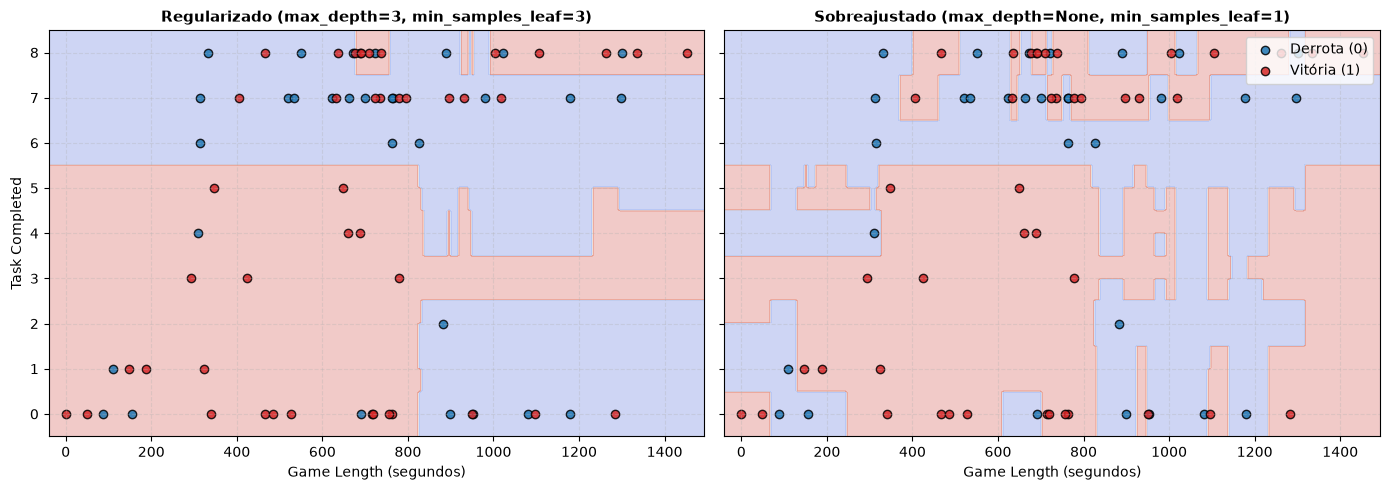

Total de erros no teste: 9 de 25 partidas


,53,80,16,14,44
Is_Imposter,0,0,0,0,1
All Tasks Completed,0,1,1,1,0
Murdered,0,1,1,1,0
Ejected,0,0,0,0,1
Task Completed,6,8,7,7,0
Imposter Kills,0,0,0,0,2
Sabotages Fixed,0,0,0,1,0
Game Length,860,1040,1086,1134,774
Real,0,1,1,1,0
Previsto,1,0,0,0,1


In [12]:
# =====================================================================
# CÉLULA 12 — Superfície de decisão 2D (regularizado x sobreajustado) e tabela de erros
# =====================================================================
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# 1. Comparação da Superfície de Decisão 2D (Regularizado vs. Sobreajustado)
# Para poder DESENHAR em 2D, treinamos modelos usando só 2 variáveis.
# (Atenção: são modelos de ilustração; o modelo final usa as 8 variáveis.)
features_2d = ['Game Length', 'Task Completed']
X_tr_2d = X_train[features_2d].values
X_te_2d = X_test[features_2d].values

modelos_2d = [
    ("Regularizado (max_depth=3, min_samples_leaf=3)",
     RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=3,
                            class_weight='balanced', random_state=42)),
    ("Sobreajustado (max_depth=None, min_samples_leaf=1)",
     RandomForestClassifier(n_estimators=100, max_depth=None, min_samples_leaf=1,
                            class_weight='balanced', random_state=42))
]

# Malha (grid) de 250x250 pontos cobrindo todo o plano; o modelo prevê a classe de cada ponto.
x_min, x_max = X_tr_2d[:, 0].min() - 40, X_tr_2d[:, 0].max() + 40
y_min, y_max = -0.5, 8.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                     np.linspace(y_min, y_max, 250))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (titulo, clf_2d) in zip(axes, modelos_2d):
    clf_2d.fit(X_tr_2d, y_train)
    # Prevê a classe de todos os pontos da malha e reformata para o formato do grid
    Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.28, cmap='coolwarm')   # fundo: azul = prevê Derrota, vermelho = prevê Vitória
    ax.scatter(X_tr_2d[y_train == 0, 0], X_tr_2d[y_train == 0, 1],
               c='#1f77b4', edgecolor='k', label='Derrota (0)', alpha=0.85)
    ax.scatter(X_tr_2d[y_train == 1, 0], X_tr_2d[y_train == 1, 1],
               c='#d62728', edgecolor='k', label='Vitória (1)', alpha=0.85)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.set_xlabel('Game Length (segundos)')
    ax.grid(True, linestyle='--', alpha=0.3)

axes[0].set_ylabel('Task Completed')
axes[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

# 2. Exibição completa (sem corte de colunas) dos erros no conjunto de teste
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Exibição transposta dos 5 primeiros erros (não corta colunas nem quebra o layout do PDF)
# [ALTERAÇÃO C] Antes: rf_bal.predict(...). Agora: modelo_final.predict(...), o modelo oficial
# avaliado nas métricas acima. Os hiperparâmetros e a semente são idênticos, então as
# previsões são exatamente as mesmas; só ficou mais claro e consistente.
y_pred_test = modelo_final.predict(X_test)
df_analise_erros = X_test.copy()
df_analise_erros['Real'] = y_test.values
df_analise_erros['Previsto'] = y_pred_test
# Real=0 e Previsto=1 -> Falso Positivo (previu Vitória, mas perdeu)
# Real=1 e Previsto=0 -> Falso Negativo (previu Derrota, mas venceu)
df_analise_erros['Erro'] = np.where(
    df_analise_erros['Real'] == 0, 'Falso Positivo', 'Falso Negativo'
)

erros_teste = df_analise_erros[df_analise_erros['Real'] != df_analise_erros['Previsto']]
print(f"Total de erros no teste: {len(erros_teste)} de {len(X_test)} partidas")
display(erros_teste.head(5).T)


### 6.1 Como ler a Superfície de Decisão 2D (Célula 12)
**O que o gráfico mostra.** O eixo X é `Game Length`, e o eixo Y é `Task Completed`. Cada ponto é uma partida de treino (**azul = Derrota**, **vermelho = Vitória**). O **fundo colorido** é o que o modelo *prevê* para cada combinação possível (azul = prevê Derrota; vermelho = prevê Vitória). Os pontos que caem na cor "errada" são partidas que o modelo erra no treino.

**Painel esquerdo, regularizado** (`max_depth=3`, `min_samples_leaf=3`): a fronteira forma **blocos retangulares grandes** e poucos degraus (lembre: cada corte é paralelo a um eixo). Aproximadamente: o modelo tende a prever **Vitória** para partidas com até ~5 tarefas e duração abaixo de ~820 s, e prever **Derrota** em faixas de 6–7 tarefas e em partidas longas com poucas tarefas. Fica claro que o modelo **não separa perfeitamente** os pontos, e isso é esperado: ele ignora ruído em vez de decorá-lo (**viés maior, variância menor**).

**Painel direito, sobreajustado** (`max_depth=None`, `min_samples_leaf=1`): a fronteira vira um **mosaico recortado**, com ilhas minúsculas em torno de pontos isolados. O modelo "encaixa" quase cada ponto de treino (**viés baixo, variância alta**), mas essas ilhas não refletem um padrão real e não deveriam se repetir em partidas novas, que é a definição visual de **overfitting**.

**Comparação:** o contraste entre os dois painéis é a mesma história da Curva 1 (treino sobe, validação cai), agora vista em geometria.

**Ressalvas:** (i) apenas 2 das 8 variáveis aparecem, então o modelo final usa mais informação do que o gráfico mostra; (ii) `Task Completed` é discreta (0–8), por isso as linhas horizontais de pontos; (iii) o comportamento é **não monotônico**: partidas com 1 a 4 tarefas tendem à Vitória quando os tripulantes ejetam o Impostor cedo, e as de 6 a 7 tarefas (sem completar todas) indicam rodadas longas em que os Impostores eliminaram a tripulação antes do fechamento das metas.


In [13]:
# =====================================================================
# CÉLULA 13 (adicionada) — Probabilidade prevista para cada erro (por que o modelo "hesitou")
# =====================================================================
# predict_proba devolve a probabilidade de Vitória. O corte padrão é 0,5:
# acima de 0,5 -> prevê Vitória; abaixo -> prevê Derrota.
# Um erro com probabilidade perto de 0,5 foi um "quase empate", não uma falha grosseira.
proba_teste = pd.Series(modelo_final.predict_proba(X_test)[:, 1], index=X_test.index)
tabela_erros = erros_teste[['Is_Imposter', 'Murdered', 'Ejected', 'All Tasks Completed',
                            'Task Completed', 'Imposter Kills', 'Game Length',
                            'Real', 'Previsto', 'Erro']].copy()
tabela_erros['P(Vitória)'] = proba_teste.loc[tabela_erros.index].round(2)
tabela_erros['Distância_de_0,5'] = (tabela_erros['P(Vitória)'] - 0.5).abs().round(2)
display(tabela_erros)

print(f"Mediana da distância até 0,5 nos erros   : {tabela_erros['Distância_de_0,5'].median():.2f}")
acertos = X_test.index.difference(erros_teste.index)
dist_acertos = (proba_teste.loc[acertos] - 0.5).abs()
print(f"Mediana da distância até 0,5 nos ACERTOS : {dist_acertos.median():.2f}")


,Is_Imposter,Murdered,Ejected,All Tasks Completed,Task Completed,Imposter Kills,Game Length,Real,Previsto,Erro,P(Vitória),"Distância_de_0,5"
53,0,0,0,0,6,0,860,0,1,Falso Positivo,0.54,0.04
80,0,1,0,1,8,0,1040,1,0,Falso Negativo,0.43,0.07
16,0,1,0,1,7,0,1086,1,0,Falso Negativo,0.38,0.12
14,0,1,0,1,7,0,1134,1,0,Falso Negativo,0.42,0.08
44,1,0,1,0,0,2,774,0,1,Falso Positivo,0.59,0.09
54,0,0,0,1,8,0,782,0,1,Falso Positivo,0.63,0.13
76,1,0,1,0,0,2,634,0,1,Falso Positivo,0.62,0.12
77,0,1,0,0,3,0,947,1,0,Falso Negativo,0.43,0.07
45,0,1,0,0,5,0,912,1,0,Falso Negativo,0.40,0.10


Mediana da distância até 0,5 nos erros   : 0.09
Mediana da distância até 0,5 nos ACERTOS : 0.12


### 6.2 Análise Qualitativa dos Casos de Erro no Conjunto de Teste

O modelo errou **9 de 25** partidas: 4 Falsos Positivos (previu Vitória, perdeu) e 5 Falsos Negativos (previu Derrota, venceu). A Célula 12 mostra os 5 primeiros; a **Célula 13 [adicionada]** lista todos os 9 com a **probabilidade prevista**, que é a chave para entender cada falha.

**Como ler:** $P(\text{Vitória}) > 0{,}5$ → o modelo prevê Vitória. Quanto mais perto de 0,5, mais "indeciso" ele estava. **Todos os erros ficam entre 0,38 e 0,63**: o modelo nunca estava confiante.

Os casos de 6.2 (os 5 mostrados na tabela transposta):

1. **Partida `53`, Falso Positivo** (P = 0,54): Tripulante (`Is_Imposter = 0`) que sobreviveu (`Murdered = 0`, `Ejected = 0`) com `6` tarefas em 860 s. O modelo previu Vitória pelo bom desempenho individual, mas a equipe perdeu porque outros tripulantes não fecharam as tarefas. *Causa estatística:* a informação decisiva (o desempenho dos **outros**) não está no dataset.
2. **Partida `44`, Falso Positivo** (P = 0,59): Impostor com `2` abates em 774 s, mas descoberto e ejetado (`Ejected = 1`). O modelo superestimou o peso dos abates frente à ejeção, e é o caso em que a árvore tem **pouquíssimos exemplos** de `Ejected = 1` para aprender (apenas 3 no treino, todos derrotas). A partida `76` (também impostor ejetado com 2 abates, P = 0,62) repete exatamente o padrão.
3. **Partidas `80`, `16` e `14`, Falsos Negativos** (P = 0,43; 0,38; 0,42): Tripulantes que completaram **todas** as tarefas (`All Tasks Completed = 1`, 7 a 8 tarefas) em partidas longas (1040 a 1134 s), mas foram assassinados (`Murdered = 1`). Como a árvore penaliza `Murdered = 1`, previu Derrota, embora a tripulação restante tenha vencido. *Geometricamente:* esses pontos caem na região "assassinado em jogo longo → Derrota", e o modelo não tem como saber que os outros nove jogadores salvaram a partida.

**Padrão geral:** quase todos os erros são partidas em que o **destino individual** (sobreviver, matar, completar tarefas) **diverge do destino coletivo**. Isso é **erro de Bayes irredutível** (ruído de rotulagem em relação às variáveis observadas): nenhum algoritmo extrairia mais sem dados dos demais jogadores.

**Sobre a matriz de confusão:** os 4 FP e 5 FN estão equilibrados (graças ao `class_weight`), sem viés forte de classe. A mediana da distância até 0,5 é 0,09 nos erros e 0,12 nos acertos, uma diferença pequena: o modelo é pouco confiante em quase tudo, o que é coerente com um AUC de ~0,7.


---

## 7. Conclusões, Limitações e Trabalhos Futuros

### Principais Conclusões
* **Adequação do algoritmo:** o Random Forest lida bem com dados tabulares mistos (binários, contagens e duração contínua), captura interações não lineares entre papel, tempo e tarefas, e **dispensa normalização**.
* **Balanceamento e regularização:** `class_weight='balanced'` aliado a `max_depth = 3` e `min_samples_leaf = 3` corrigiu o viés pró-classe majoritária: o **recall de Derrota subiu de 0,27 para 0,64** e o F1 macro de 0,51 para 0,64 (Célula 9).
* **Desempenho final no teste (N=25):** acurácia **0,64**, F1 macro **0,64**, ROC-AUC **0,695**. Na validação cruzada: F1 (Vitória) 0,64 ± 0,07 e AUC 0,61 ± 0,08.
* **Leitura realista:** o classificador trivial "sempre Vitória" acerta 14 de 25 (**56%**) no teste; nosso modelo acerta 16 (**64%**). O ganho é de **2 partidas** e não é estatisticamente conclusivo. O modelo contém algum sinal (principalmente `Murdered` e tarefas), mas **fraco**.
* **Diagnóstico viés–variância:** as curvas mostram overfitting crescente com a profundidade e a superfície 2D ilustra o contraste entre fronteiras suaves e recortadas.
* **Importância de variáveis:** a alta importância de Gini de `Game Length` não se sustentou na permutation importance do teste, sugerindo ajuste ao treino.

### Limitações Estruturais
1. **Observabilidade parcial (telemetria unilateral):** só o Player 1 é observado num jogo coletivo de até 10 jogadores, o que gera ruído irredutível.
2. **Tamanho amostral ($N = 100$):** com 25 partidas no teste, cada erro vale 4 pontos de acurácia; as estimativas têm grande incerteza.
3. **Informação pós-jogo:** as features são conhecidas só no fim da partida (modelo descritivo, não preditivo em tempo real).
4. **Registro suspeito:** 1 partida com duração 0 s foi mantida no dataset.

### Trabalhos Futuros
* Incorporar logs dos demais jogadores e histórico de votações.
* Criar *features* de taxa temporal (`tasks_por_minuto = Task Completed / (Game Length / 60)`).
* Aplicar **Repeated Stratified K-Fold** para estabilizar as estimativas e intervalos de confiança.
* Comparar com outros algoritmos (Gradient Boosting, Regressão Logística) e usar *permutation importance* repetida em validação cruzada.

---

## Glossário final
* **Bagging:** treinar vários modelos em amostras *bootstrap* e agregar as previsões.
* **Bootstrap:** amostra com reposição do mesmo tamanho do conjunto original.
* **Out-of-bag (OOB):** partidas não sorteadas por uma árvore; servem de validação gratuita.
* **Gini:** medida de impureza de um nó; 0 = puro, 0,5 = 50/50 (2 classes).
* **Ganho de Gini:** redução de impureza gerada por um corte.
* **Feature bagging:** sortear só $m=\lfloor\sqrt{p}\rfloor$ atributos candidatos por nó.
* **Recall / Precisão / F1:** ver tabela da seção 5.
* **ROC-AUC:** probabilidade de ordenar corretamente um par (vitória, derrota).
* **K-Fold:** validação em K partes alternadas.
* **Overfitting / Underfitting:** decorar o ruído / ser simples demais.
* **Erro de Bayes:** erro mínimo inevitável dado o que as features conseguem informar.
